<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta4_g%C3%B6rev6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

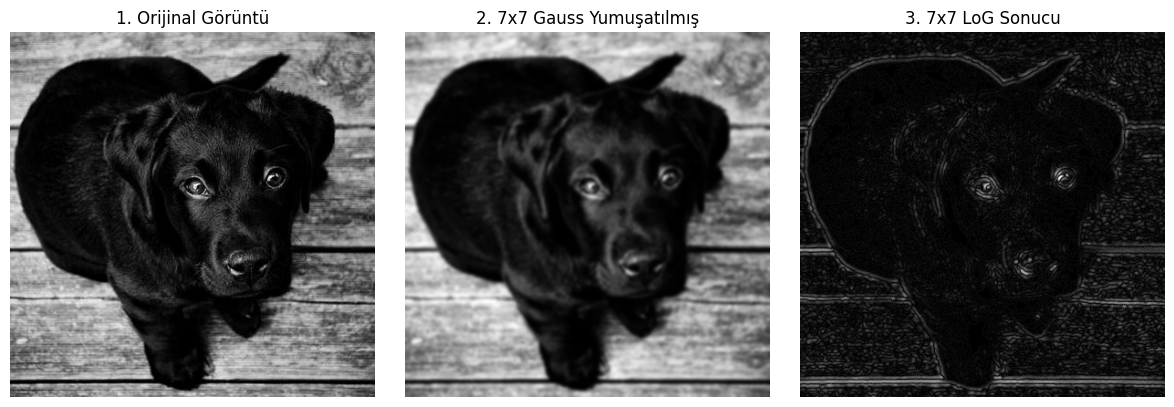

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Test için örnek bir görüntü indirelim
url = 'https://picsum.photos/id/237/400/400'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_GRAYSCALE)

# 2. 7x7 Boyutunda Laplacian of Gaussian (LoG) Uygulaması
# Önce 7x7 Gauss ile yumuşatıp, sonra Laplacian alıyoruz (LoG mantığı budur)
blurred_7x7 = cv2.GaussianBlur(img, (7, 7), sigmaX=1.5)
log_img = cv2.Laplacian(blurred_7x7, cv2.CV_64F)
log_img_abs = cv2.convertScaleAbs(log_img)

# 3. Sonuçları Görselleştirme
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Orijinal Görüntü')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred_7x7, cmap='gray')
plt.title('2. 7x7 Gauss Yumuşatılmış')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(log_img_abs, cmap='gray')
plt.title('3. 7x7 LoG Sonucu')
plt.axis('off')

plt.tight_layout()
plt.show()

LoG (Laplacian of Gaussian) ve Diğer Kenar Filtreleri Karşılaştırma RaporuBu çalışmada, öncekilerden farklı olarak $7 \times 7$ boyutunda LoG (Laplacian of Gaussian) filtresini test ettim ve elde ettiğim sonuçları daha önce yaptığımız Gauss'lu ve Gauss'suz diğer kenar filtreleriyle (Sobel, Prewitt, saf Laplacian) kıyasladım.1. LoG (Laplacian of Gaussian) Ne Yapıyor?Normalde düz Laplacian filtresi resimdeki ufak pürüzlere ve gürültülere karşı çok hassastır; resmi direkt Laplacian'a soktuğumuzda her yer karıncalı gibi minik çizgilerle doluyordu.LoG ise bu sorunu çözmek için harika bir yöntemdir: Önce resmi geniş bir alanla ($7 \times 7$ Gauss ile) güzelce yumuşatır, gürültüleri yok eder; ardından Laplacian filtresini uygular. Böylece hem gürültülerden kurtulmuş oluruz hem de nesnenin gerçek kenarlarını çok daha temiz yakalarız.2. Diğer Filtrelerle KıyaslamaGauss Filtresi Olmadan Çalıştırılanlar (Saf Laplacian / Prewitt / Sobel):Eğer resme hiç Gauss uygulamadan direkt filtreleri çalıştırırsak, resimdeki pürüzler ve piksel geçişleri kenar gibi algılanıyor. Sonuç aşırı gürültülü ve kirli çıkıyor.Gauss Geçirilmiş Sobel ve Prewitt:Bu ikisi yönlü çalışır (biri yatay, diğeri dikey). Resmi önce yumuşatıp sonra Sobel uygularsak kalın, belirgin ve temiz hatlar elde ediyoruz. Ancak Sobel ve Prewitt tek yöne odaklandığı için detayları yakalamakta bazen yetersiz kalabiliyor.7x7 LoG Filtresi:Geniş bir pencere ($7 \times 7$) kullandığı için resmi çok daha iyi yumuşatıyor. Laplacian'ın o hassas ve gürültüye meyilli yapısını, baştaki güçlü Gauss ile törpülemiş oluyor. Sonuçta ortaya çok ince ama bir o kadar da doğru ve gürültüden arındırılmış kenar çizgileri çıkıyor.